# FLOOD HISTORY EDA

- The goal of this notebook is to identify and understand where and when these floods happen in Kenya.

**Data Used:**
1) desinventar_floods_county_month.csv (shows the county months with records of floods from 2002-2025)
2) kenya_counties.geojson (Shows the counties and their boundaries)
3) kenya_county_crosswalk.csv (Shows the county names and code identifiers)

# Data Loading and Cleaning

In [75]:
import pandas as pd # Used for Data loading and manipulation
import matplotlib.pyplot as plt # Used for Data Visualization
import seaborn as sns # Used for Data Visualization
import numpy as np # Used to perform statistics and mathematical operations
import geopandas as gpd # Used to load and manipulate any geographical file

Importing the libraries we need to perform Data Loading, Data Cleaning and Exploratory Data Analysis. Roles of the libraries are explained using the comments.

In [76]:
floods_county_month = pd.read_csv("desinventar_floods_county_month.csv")
floods_county_month

,pcode,county,year,month,flood_records,deaths,directly_affected,flood_occurred
0,KE012,Meru,2002,5,4,14,0,1
1,KE014,Embu,2002,5,1,6,0,1
2,KE015,Kitui,2002,5,2,2,0,1
3,KE016,Machakos,2002,5,1,1,0,1
4,KE020,Kirinyaga,2002,5,1,1,0,1
...,...,...,...,...,...,...,...,...
328,KE008,Wajir,2023,11,1,0,0,1
329,KE032,Nakuru,2024,4,2,40,0,1
330,KE016,Machakos,2024,5,1,0,0,1
331,KE034,Kajiado,2024,5,1,0,0,1


Loading and displaying the contents of the dataset

In [77]:
floods_county_month.info() # Displays the column names and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   pcode              333 non-null    object
 1   county             333 non-null    object
 2   year               333 non-null    int64 
 3   month              333 non-null    int64 
 4   flood_records      333 non-null    int64 
 5   deaths             333 non-null    int64 
 6   directly_affected  333 non-null    int64 
 7   flood_occurred     333 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 20.9+ KB


Displaying the column names and datatypes from the dataset

In [78]:
floods_county_month.describe()

,year,month,flood_records,deaths,directly_affected,flood_occurred
count,333.000000,333.000000,333.000000,333.000000,333.000000,333.0
mean,2011.006006,6.306306,2.261261,1.825826,0.909910,1.0
std,4.303959,3.692534,2.986047,4.610719,16.440226,0.0
min,2002.000000,1.000000,1.000000,0.000000,0.000000,1.0
25%,2009.000000,4.000000,1.000000,0.000000,0.000000,1.0
50%,2010.000000,5.000000,1.000000,0.000000,0.000000,1.0
75%,2013.000000,11.000000,2.000000,2.000000,0.000000,1.0
max,2025.000000,12.000000,35.000000,40.000000,300.000000,1.0


Displaying any statistical information from the dataset

In [79]:
floods_county_month.shape

(333, 8)

Displaying the size of the dataset

In [80]:
floods_county_month.duplicated(['county', 'year', 'month']).sum()

np.int64(0)

Checking if there are any duplicated values in our dataset

In [81]:
floods_county_month.nunique()

,0
pcode,46
county,46
year,20
month,12
flood_records,14
deaths,19
directly_affected,3
flood_occurred,1


We have 46 counties in the dataset, which means there is one county missing

In [82]:
floods_county_month['county'].value_counts()

,count
county,
Kisumu,18
Turkana,15
Tana River,14
Kilifi,14
Nakuru,13
Machakos,13
Nairobi,13
Kajiado,13
Busia,12


Using value_counts() to check how many counties appear on the dataset, also used to check whether there are any counties missing

We're missing information from NYAMIRA county

In [83]:
floods_county_month[['year', 'month']].agg(['min', 'max'])

,year,month
min,2002,1
max,2025,12


Checking if the year and month ranges are accurate

In [84]:
floods_county_month['year'].value_counts()

,count
year,
2010,72
2015,48
2012,34
2009,33
2013,32
2008,24
2002,21
2011,17
2006,13


Using value counts to help check how many times the years appear on the text. Also used to check whether if there are any years missing.

This confirms that we are missing data from the year 2004, 2017, 2018, and 2019

In [85]:
# Constructing a date column
floods_county_month['date'] = pd.to_datetime(dict(year= floods_county_month['year'], month = floods_county_month['month'], day= 1))
floods_county_month

,pcode,county,year,month,flood_records,deaths,directly_affected,flood_occurred,date
0,KE012,Meru,2002,5,4,14,0,1,2002-05-01
1,KE014,Embu,2002,5,1,6,0,1,2002-05-01
2,KE015,Kitui,2002,5,2,2,0,1,2002-05-01
3,KE016,Machakos,2002,5,1,1,0,1,2002-05-01
4,KE020,Kirinyaga,2002,5,1,1,0,1,2002-05-01
...,...,...,...,...,...,...,...,...,...
328,KE008,Wajir,2023,11,1,0,0,1,2023-11-01
329,KE032,Nakuru,2024,4,2,40,0,1,2024-04-01
330,KE016,Machakos,2024,5,1,0,0,1,2024-05-01
331,KE034,Kajiado,2024,5,1,0,0,1,2024-05-01


Combining years and months into the first day of the month (eg: 2023-11-01) to help make plotting easier

In [86]:
fixed_floods = floods_county_month.to_csv("desinventar_floods_with_pcode_and_date.csv", index= False)

Saving a copy of the dataset with all the amendments

In [87]:
counties = pd.read_csv("kenya_county_crosswalk.csv")
counties

,county,knbs_code,pcode,desinventar_code,desinventar_name
0,Mombasa,1,KE001,28,MOMBASA
1,Kwale,2,KE002,19,KWALE
2,Kilifi,3,KE003,14,KILIFI
3,Tana River,4,KE004,40,TANA-RIVER
4,Lamu,5,KE005,21,LAMU
5,Taita-Taveta,6,KE006,39,TAITA-TAVETA
6,Garissa,7,KE007,6,GARISSA
7,Wajir,8,KE008,46,WAJIR
8,Mandera,9,KE009,24,MANDERA
9,Marsabit,10,KE010,25,MARSABIT


Loading the dataset and displaying it

In [88]:
counties.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   county            47 non-null     object
 1   knbs_code         47 non-null     int64 
 2   pcode             47 non-null     object
 3   desinventar_code  47 non-null     int64 
 4   desinventar_name  47 non-null     object
dtypes: int64(2), object(3)
memory usage: 2.0+ KB


Checking the dataset's column names and data types

In [89]:
counties.shape

(47, 5)

Checking the size of the dataset

# EXPLORATORY DATA ANALYSIS

## 1) Floods per year

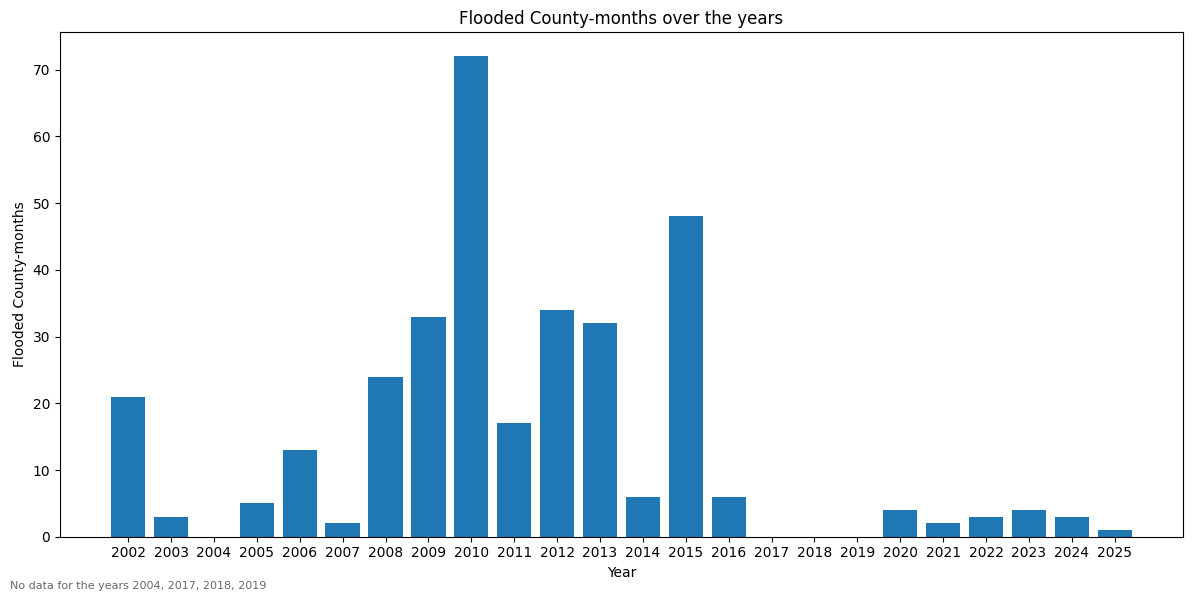

In [90]:
# Floods per year
floods_per_year = floods_county_month.groupby("year").size().reindex(range(2002, 2026))

fig, ax = plt.subplots(figsize= (12, 6))
ax.bar(floods_per_year.index, floods_per_year.fillna(0))
ax.set_title("Flooded County-months over the years")
ax.set_xlabel("Year")
ax.set_ylabel("Flooded County-months")
ax.set_xticks(list(range(2002,2026)))
fig.text(0.01, 0.01, "No data for the years 2004, 2017, 2018, 2019", fontsize= 8, color= 'dimgrey')
fig.savefig("chart1.png", dpi= 150)
plt.tight_layout()
plt.show()

A flooded county month basically means if a county floods in 2 different months, we are to count it twice. Years with no data are indicated below the chart.

## 2) Floods per calendar month

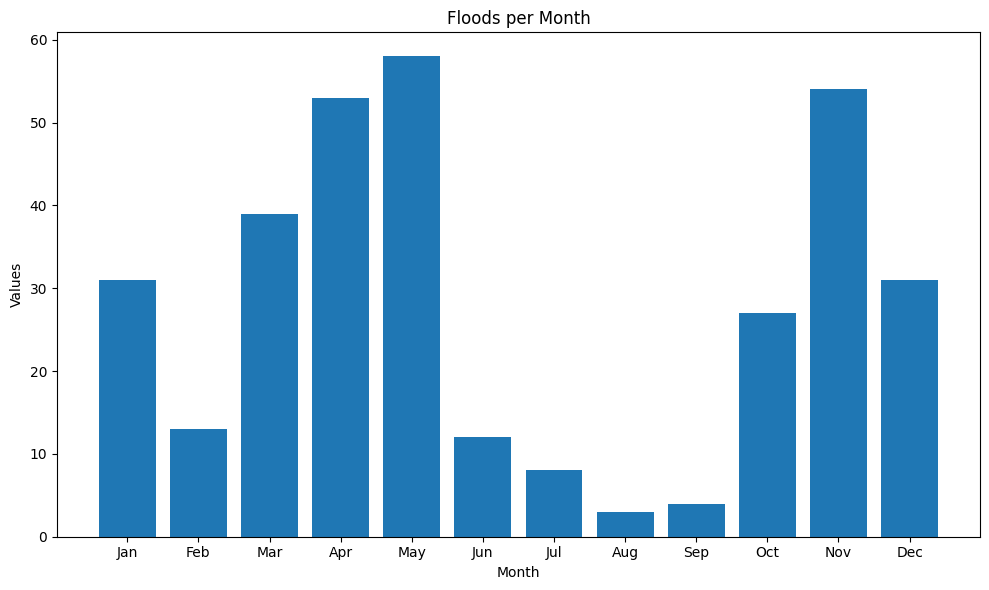

In [91]:
floods_per_month = floods_county_month.groupby('month').size().reindex(range(1,13))

fig, ax= plt.subplots(figsize= (10,6))
ax.bar(floods_per_month.index, floods_per_month.values)
ax.set_title("Floods per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Values")
ax.set_xticks(range(1,13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
fig.savefig("chart2.png", dpi= 150)
plt.tight_layout()
plt.show()

This barchart displays the number of flooded county-months per month summed up across all years. It also shows how the two rainy seasons (April-May and November) impacted the country over the years

## 3) Top 15 counties with the most floods

/tmp/ipykernel_1229/2728383449.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = top_15.values, y= top_15.index, palette= 'viridis')


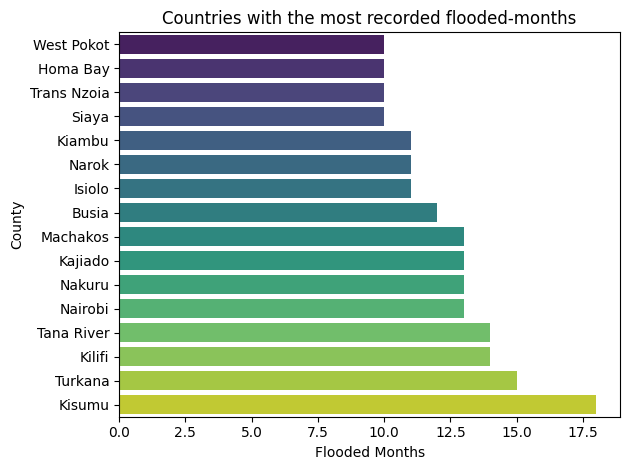

In [92]:
floods_sorted = floods_county_month.groupby('county').size().sort_values(ascending= False)
top_15 = floods_sorted.nlargest(15, keep= 'all').sort_values(ascending= True) # This will collect the 15 largest values (Counties in this context)

sns.barplot(x = top_15.values, y= top_15.index, palette= 'viridis')
plt.title("Countries with the most recorded flooded-months")
plt.xlabel("Flooded Months")
plt.ylabel("County")
plt.savefig("chart3.png", dpi= 150)
plt.tight_layout()
plt.show()

Another simple barchart showing the counties with the most recorded flooded months. There are counties that are tied with the same amount of flooded months, so the chart shows 16 counties instead of the planned 15.

## 4) Choropleth Map showing the counties with the highest risk of flooding

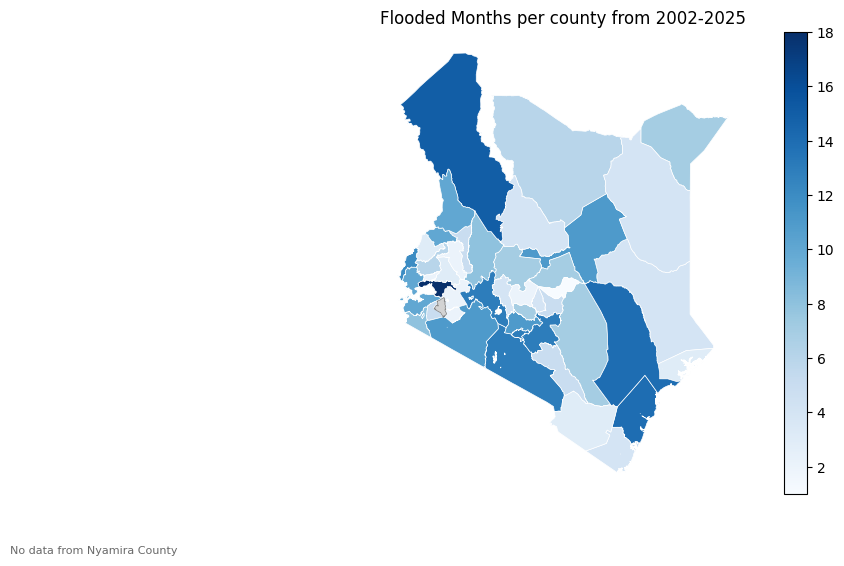

In [93]:
counties_map = gpd.read_file("kenya_counties.geojson")

counts = floods_county_month.groupby("pcode").size().rename("flooded_months")
df = counties_map.merge(counts, on= 'pcode', how= 'left')

fig, ax = plt.subplots(figsize= (10,6))
df.plot(column= 'flooded_months', cmap= 'Blues', edgecolor= 'white', linewidth= 0.5, legend= True, missing_kwds= {"color": "lightgrey", "edgecolor": "grey", "label": "No data (NYAMIRA)"}, ax= ax)
fig.text(0.01, 0.01, "No data from Nyamira County", fontsize= 8, color= 'dimgrey')
ax.set_axis_off()
ax.set_title("Flooded Months per county from 2002-2025")
fig.savefig("chart4.png", dpi=150)
plt.show()

Visual representation of how floods impact each county. The darker the colour the more the flooded months are reported. Nyamira is coloured grey because there is no data coming from there, as indicated at the bottom of the chart

## 5) Heatmap showing the years that were affected the most by floods

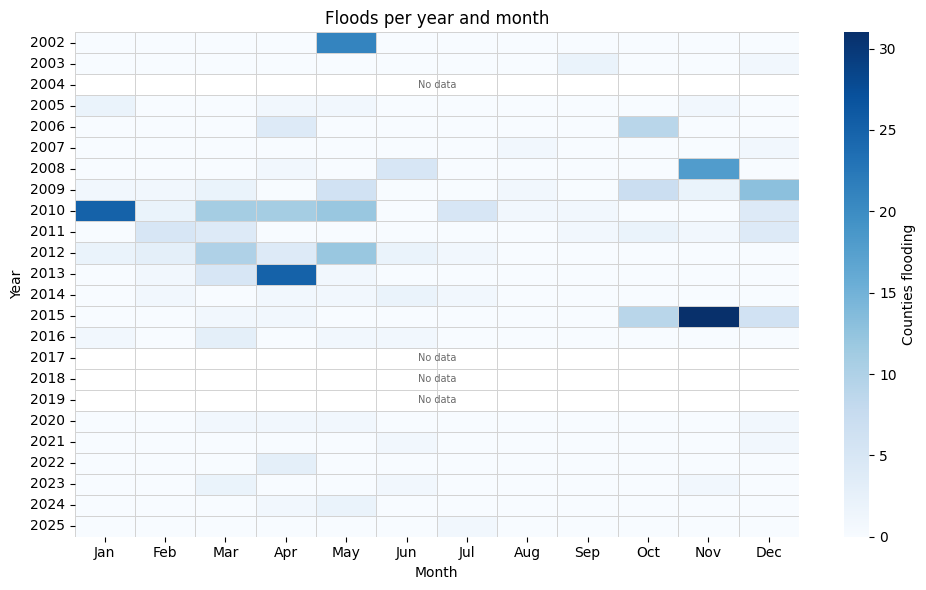

In [94]:
no_years = [2004, 2017, 2018, 2019]
years = range(2002, 2026)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

grid = floods_county_month.groupby(['year', 'month'])['county'].nunique().unstack("month").reindex(index= years, columns= range(1,13))
grid = grid.fillna(0)
grid.loc[no_years] = np.nan
grid.columns = month_names

fig, ax = plt.subplots(figsize=(10,6))
sns.heatmap(grid, cmap='Blues', linewidths= 0.5, linecolor= 'lightgrey', cbar_kws= {'label': 'Counties flooding'}, ax= ax)

for i in no_years:
  row = list(grid.index).index(i)
  ax.text(6, row + 0.5, "No data", ha= 'center', va= 'center', fontsize= 7, color= 'dimgrey')

ax.set_title("Floods per year and month")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
ax.tick_params(axis= 'y', rotation = 0)
fig.savefig("chart5.png", dpi= 150)
plt.tight_layout()
plt.show()

Each square represents a month and a year, coloured by different counties that flooded within that particular month and year. Darker colours represent big flood events, while lighter colours means there was little to no floods recorded at that timeframe. The years that contain no data are marked 'No data'

## 6) Deaths per year

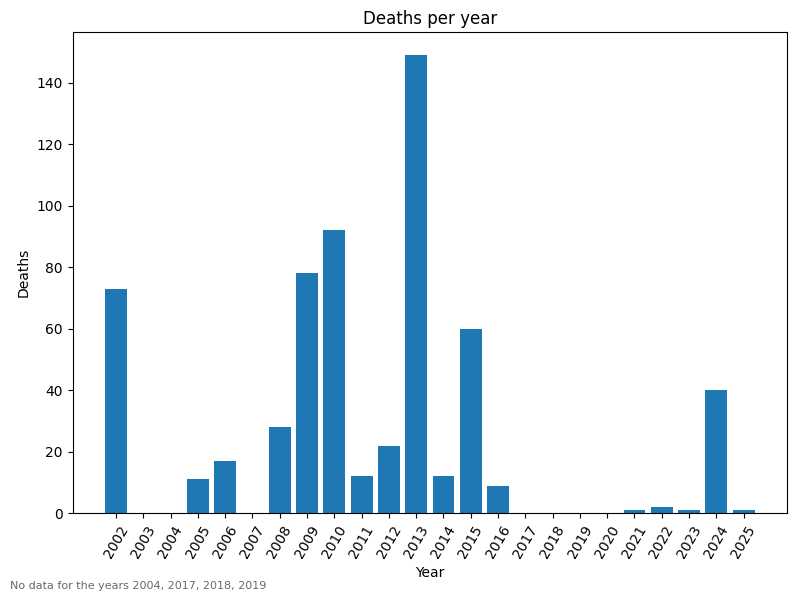

In [95]:
death_per_year = floods_county_month.groupby('year')['deaths'].sum().reindex(range(2002,2026))

fig, ax = plt.subplots(figsize= (8,6))
ax.bar(death_per_year.index, death_per_year.fillna(0))
ax.set_title("Deaths per year")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths")
ax.set_xticks(list(range(2002,2026)))
ax.tick_params(axis= 'x', rotation = 60)
fig.text(0.01, 0.01, "No data for the years 2004, 2017, 2018, 2019", fontsize= 8, color= 'dimgrey')
plt.tight_layout()
fig.savefig("chart6.png", dpi=150)
plt.show()

This bar chart simply demonstrates the number of deaths reported every year. This is only used for context, as it gives us an idea on how much of an impact a flood can have on the people of Kenya. The years that contain no data are indicated at the bottom of the chart.

## FINDINGS

- After analyzing the datasets provided, we can see that both rainy seasons show up (April-May and October-November) as they recorded the most rainfall compared to the rest. 2010 and 2015 were the biggest years, but 2013 was the deadliest with nearly 150 deaths despite it having fewer flooded county months than 2010 and 2015. In terms of counties, Kisumu was the most impacted with 18 months of floods, with Tana River and Nairobi being among the top too, so flooding is not limited to the coast and lake regions. However there are no records for 2004, 2017, 2018, 2019 (which some were serious flood years) and for Nyamira County, and there is a noticeable decline in flooded county months from 2020-2025, which looks like thin reporting rather than fewer floods.